# 01 · Análisis exploratorio (EDA)
**Responsables:** Santiago (análisis) y Luciana (versión final de gráficos) · **Módulo 1**

**Objetivo.** Entender la forma de cada variable acústica, sus relaciones y sus problemas (sesgo, outliers,
redundancia) para justificar con evidencia las decisiones de preprocesamiento del notebook 02.

Todos los gráficos se guardan en `reports/figures/` para usarlos en el informe y en el dashboard.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config as cfg
from src import preprocessing as pp
from src import viz

viz.set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Datos limpios y bitácora de limpieza

In [2]:
raw = pp.load_raw()
df, log = pp.clean(raw)
cfg.TABLES.mkdir(parents=True, exist_ok=True)
log.to_csv(cfg.TABLES / "bitacora_limpieza.csv", index=False)
log

,paso,filas_antes,filas_despues,descartadas
0,nulos en variables/identificadores,114000,114000,0
1,tempo = 0 o duración = 0,114000,113842,158
2,duplicados por track_id,113842,89583,24259
3,duplicados por artista + nombre,89583,81198,8385
4,TOTAL,114000,81198,32802


## 2. Distribución de cada variable
Buscamos asimetrías fuertes, que distorsionan a K-Means y a PCA (ambos son sensibles a la escala y a valores extremos).

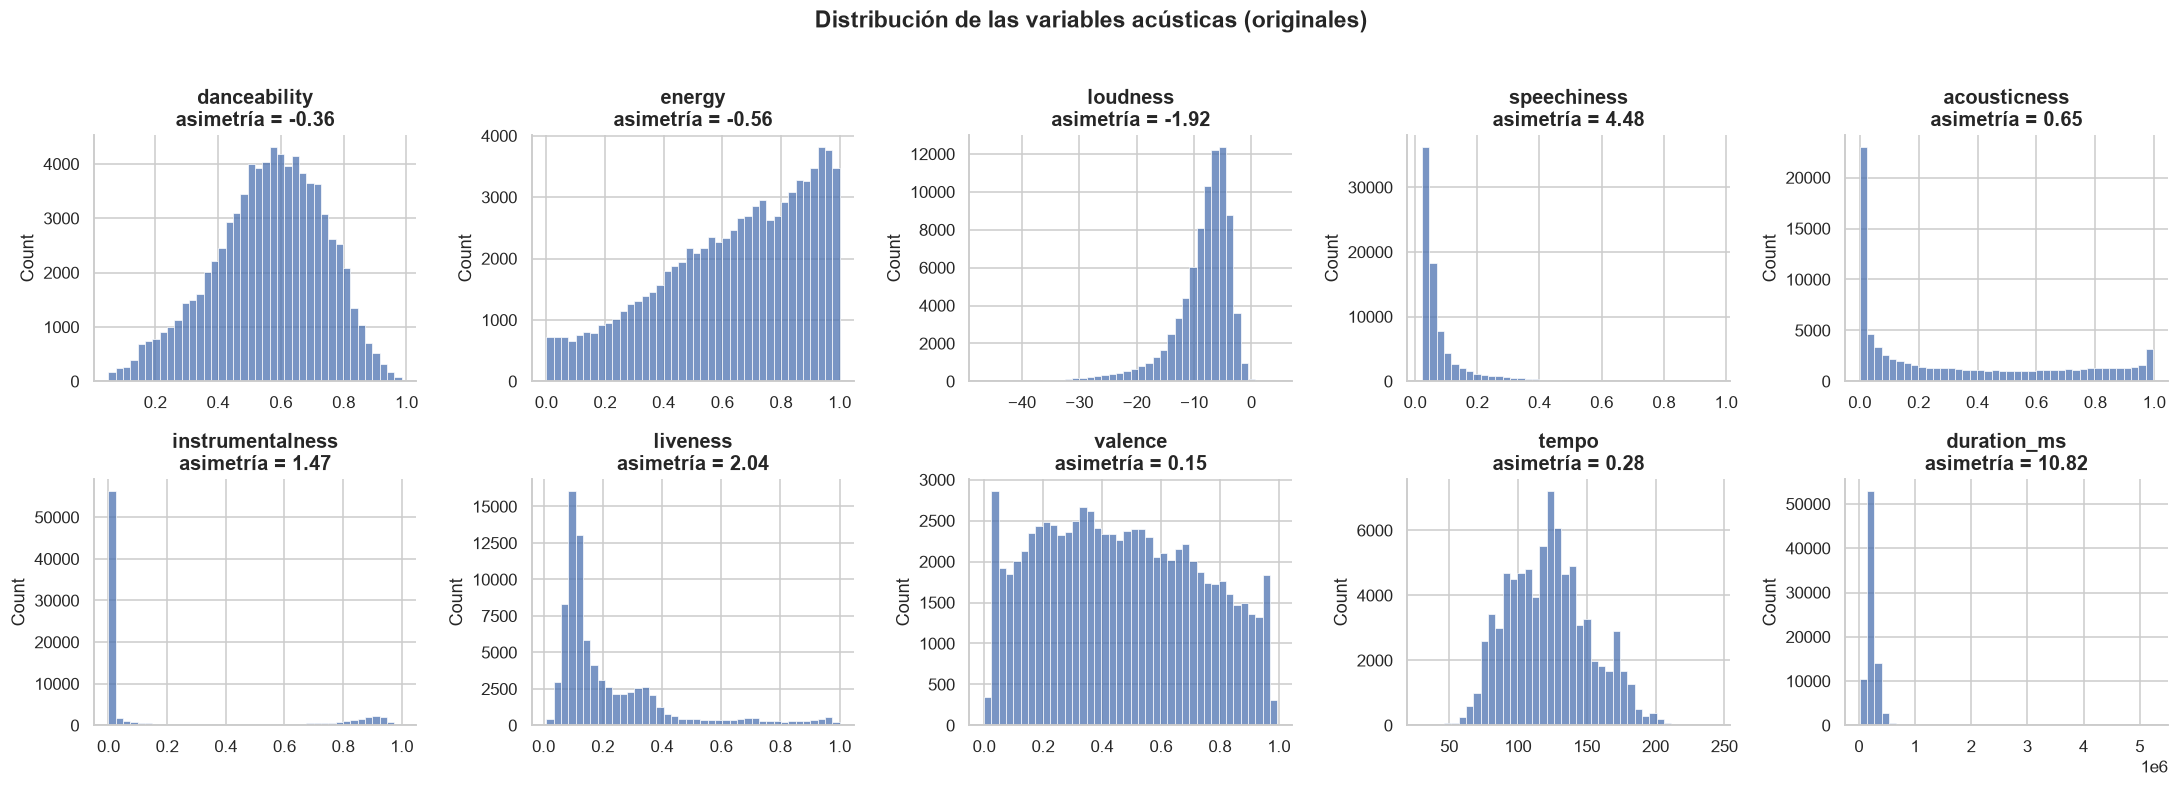

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, f in zip(axes.ravel(), cfg.FEATURES):
    sns.histplot(df[f], bins=40, ax=ax, color=viz.PALETTE[0])
    ax.set_title(f"{f}\nasimetría = {df[f].skew():.2f}")
    ax.set_xlabel("")
fig.suptitle("Distribución de las variables acústicas (originales)", y=1.02, fontsize=15, fontweight="bold")
fig.tight_layout()
viz.save_fig(fig, "eda_01_distribuciones")
plt.show()

## 3. Valores extremos (regla del IQR)

In [4]:
out = pp.iqr_outlier_report(df)
out.to_csv(cfg.TABLES / "eda_outliers_iqr.csv")
out[["n_outliers", "pct_outliers", "asimetria"]].sort_values("pct_outliers", ascending=False)

,n_outliers,pct_outliers,asimetria
variable,,,
instrumentalness,17310,21.318,1.470
speechiness,9687,11.930,4.484
liveness,6479,7.979,2.036
loudness,4561,5.617,-1.916
duration_ms,3777,4.652,10.824
tempo,307,0.378,0.278
danceability,256,0.315,-0.360
energy,0,0.000,-0.558
acousticness,0,0.000,0.648


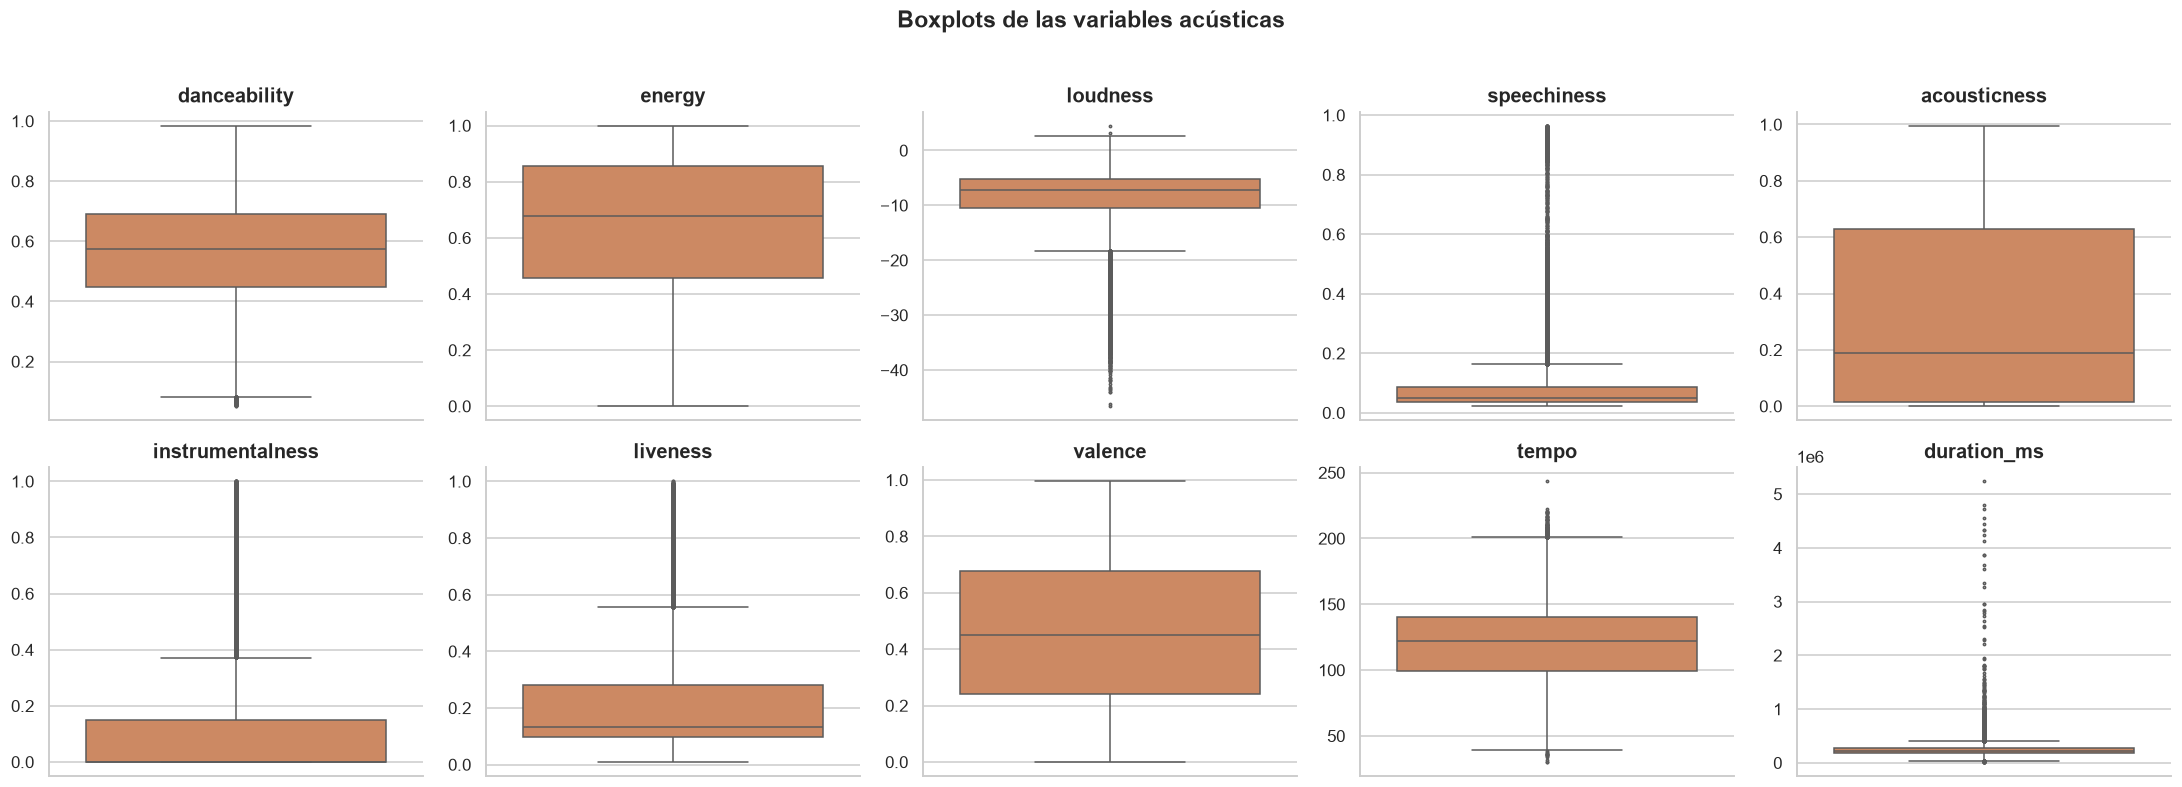

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, f in zip(axes.ravel(), cfg.FEATURES):
    sns.boxplot(y=df[f], ax=ax, color=viz.PALETTE[1], fliersize=1.5)
    ax.set_title(f)
    ax.set_ylabel("")
fig.suptitle("Boxplots de las variables acústicas", y=1.02, fontsize=15, fontweight="bold")
fig.tight_layout()
viz.save_fig(fig, "eda_02_boxplots")
plt.show()

## 4. Efecto de la transformación logarítmica
Aplicamos `log1p` solo a las variables con cola larga a la derecha (`cfg.LOG_FEATURES`) y comparamos la asimetría
antes y después. Si la transformación no reduce la asimetría de una variable, **debe salir de la lista** en `src/config.py`.

In [6]:
X = pp.transform_features(df)
comp = pd.DataFrame({
    "asimetria_antes": df[cfg.FEATURES].skew(),
    "asimetria_despues": X.skew(),
})
comp["transformada"] = comp.index.isin(cfg.LOG_FEATURES)
comp

,asimetria_antes,asimetria_despues,transformada
danceability,-0.360,-0.360,False
energy,-0.558,-0.558,False
loudness,-1.916,-1.916,False
speechiness,4.484,3.640,True
acousticness,0.648,0.648,False
instrumentalness,1.470,1.395,True
liveness,2.036,1.689,True
valence,0.152,0.152,False
tempo,0.278,0.278,False
duration_ms,10.824,-0.338,True


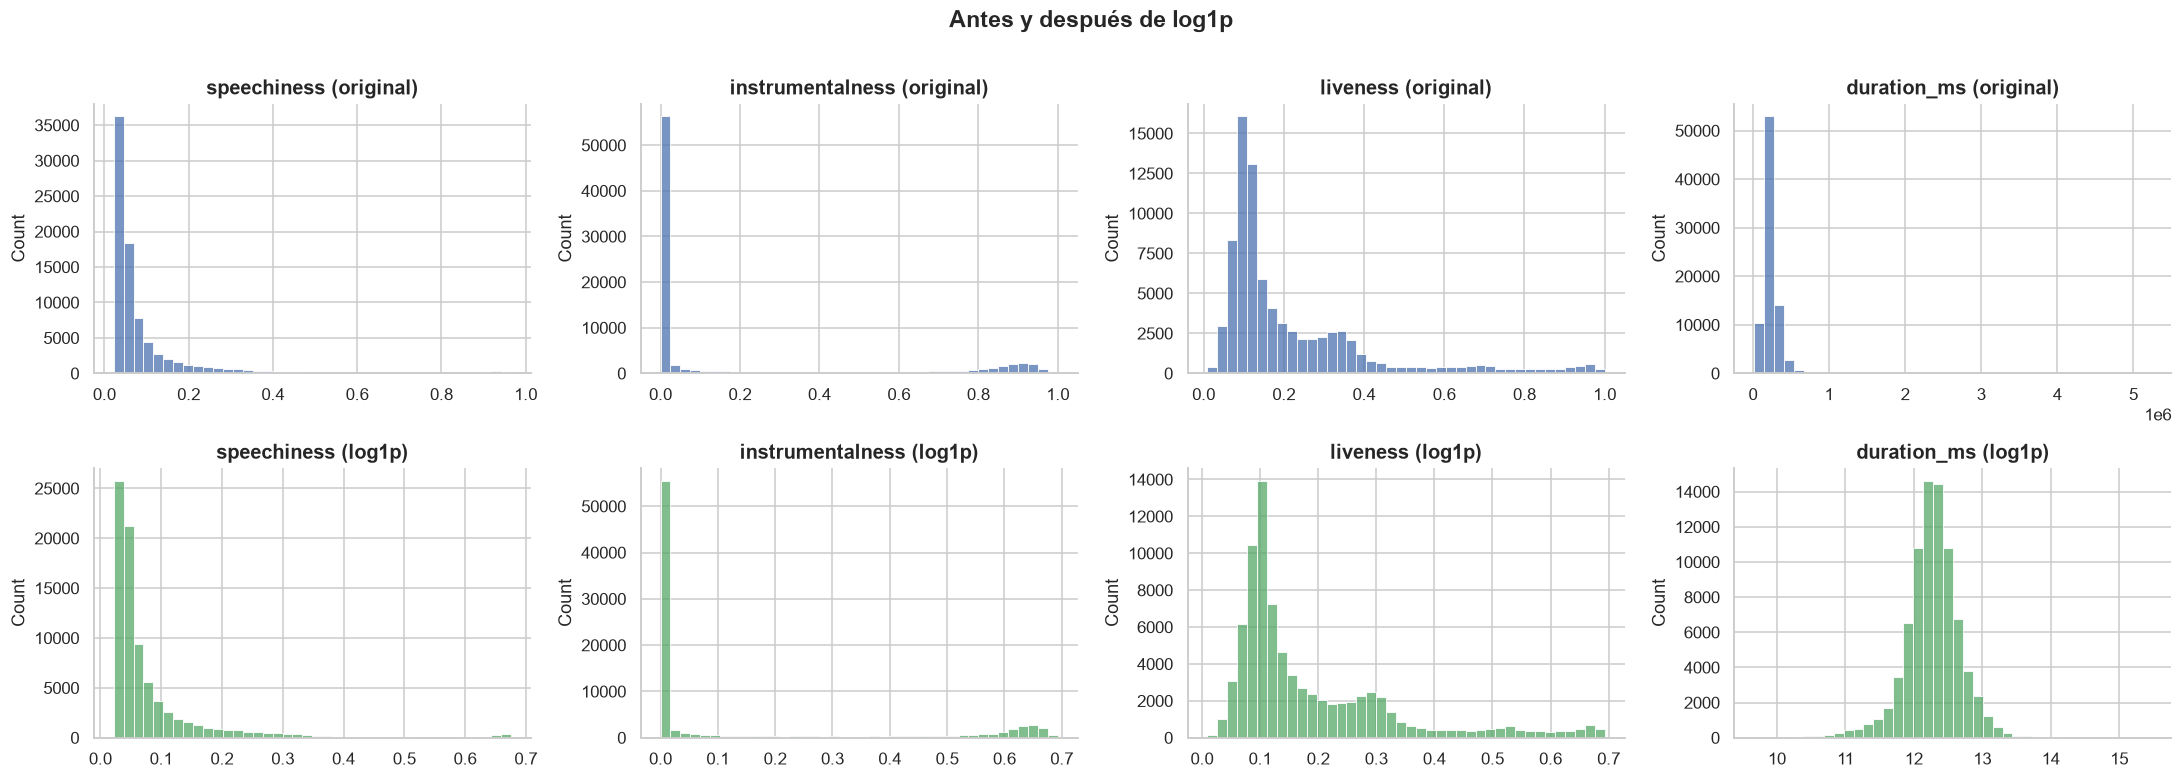

In [7]:
fig, axes = plt.subplots(2, len(cfg.LOG_FEATURES), figsize=(5 * len(cfg.LOG_FEATURES), 7))
for j, f in enumerate(cfg.LOG_FEATURES):
    sns.histplot(df[f], bins=40, ax=axes[0, j], color=viz.PALETTE[0]); axes[0, j].set_title(f"{f} (original)")
    sns.histplot(X[f], bins=40, ax=axes[1, j], color=viz.PALETTE[2]); axes[1, j].set_title(f"{f} (log1p)")
    for r in (0, 1): axes[r, j].set_xlabel("")
fig.suptitle("Antes y después de log1p", y=1.01, fontsize=15, fontweight="bold")
fig.tight_layout()
viz.save_fig(fig, "eda_03_antes_despues_log")
plt.show()

## 5. Correlaciones
Pares muy correlacionados (|r| > 0.7) aportan información redundante; es justo el caso donde PCA ayuda.

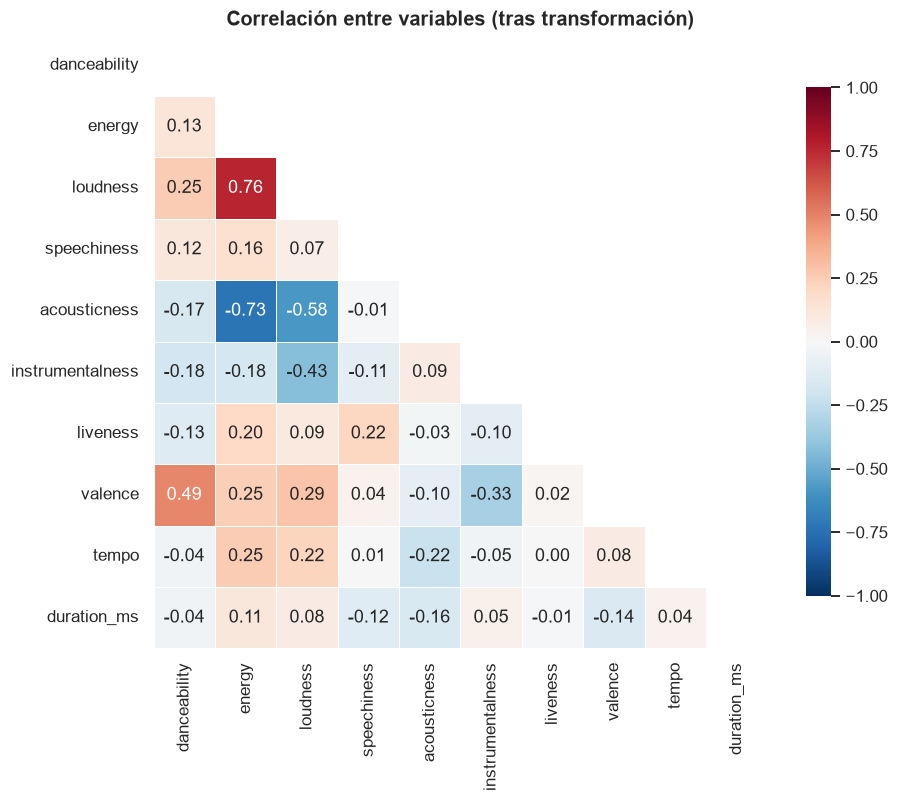

,var_1,var_2,r,abs_r
21,loudness,energy,0.761,0.761
41,acousticness,energy,-0.733,0.733
42,acousticness,loudness,-0.584,0.584
70,valence,danceability,0.488,0.488
52,instrumentalness,loudness,-0.427,0.427
75,valence,instrumentalness,-0.332,0.332
72,valence,loudness,0.285,0.285
20,loudness,danceability,0.255,0.255


In [8]:
corr = X.corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, linewidths=.5, cbar_kws={"shrink": .8}, ax=ax)
ax.grid(False)
ax.set_title("Correlación entre variables (tras transformación)")
viz.save_fig(fig, "eda_04_correlaciones")
plt.show()

pares = (corr.where(~mask).stack().rename("r").reset_index()
         .rename(columns={"level_0": "var_1", "level_1": "var_2"}))
pares["abs_r"] = pares["r"].abs()
pares.sort_values("abs_r", ascending=False).head(8)

## 6. Balance de géneros
El género **no** entra al clustering. Se analiza ahora solo para saber con qué material contaremos al comparar
clusters contra géneros en el notebook 06.

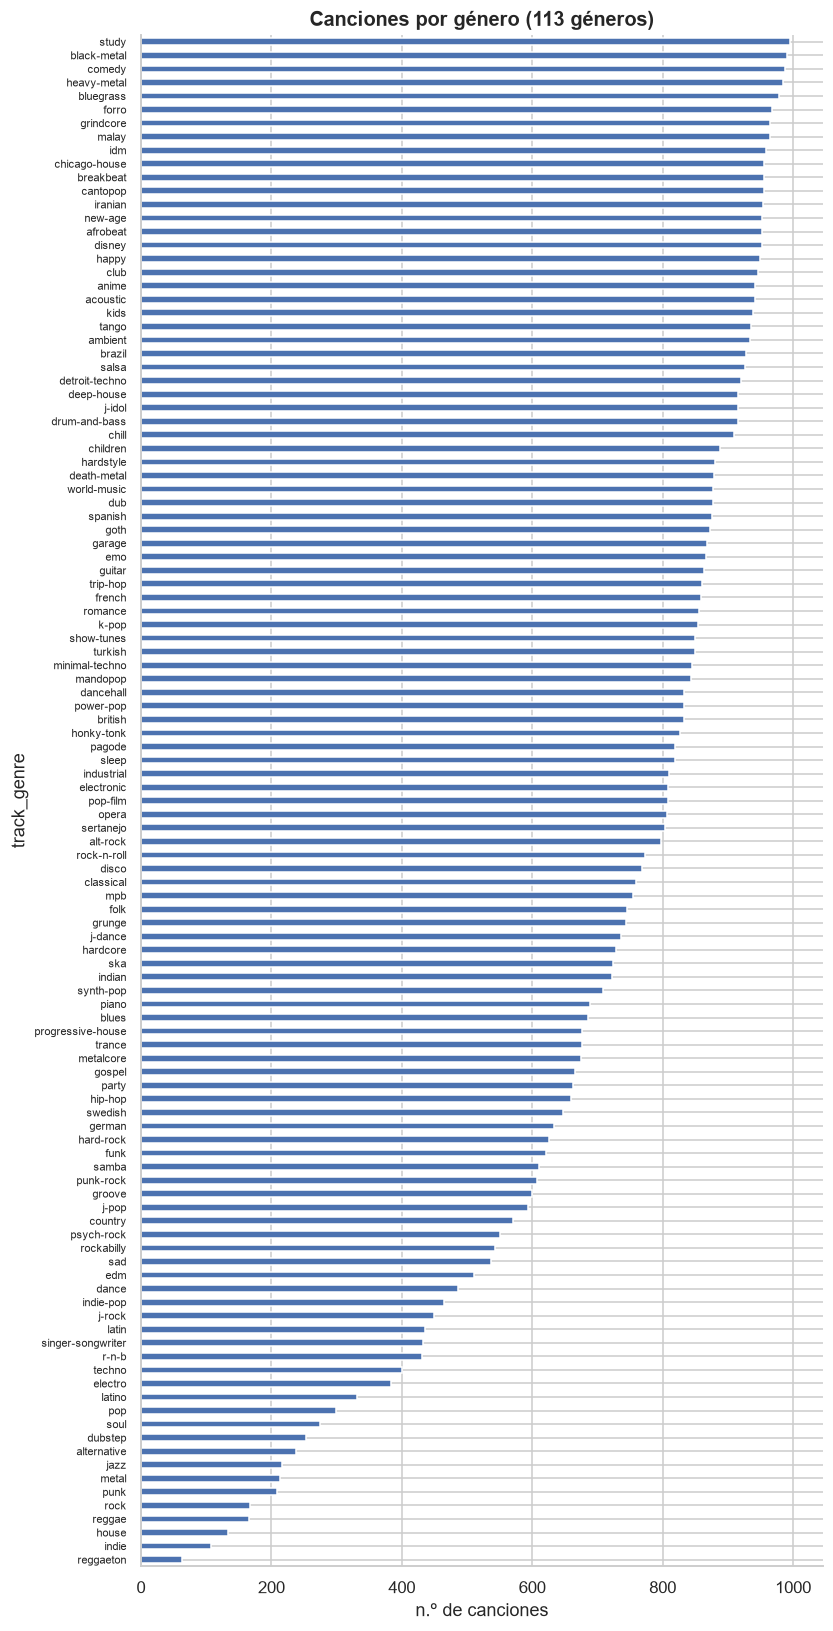

count   113.000
mean    718.566
std     241.486
min      63.000
25%     608.000
50%     808.000
75%     915.000
max     996.000
Name: count, dtype: float64

In [9]:
conteo = df[cfg.GENRE_COL].value_counts()
fig, ax = plt.subplots(figsize=(8, max(4, 0.16 * len(conteo))))
conteo.sort_values().plot.barh(ax=ax, color=viz.PALETTE[0])
ax.set_title(f"Canciones por género ({len(conteo)} géneros)")
ax.set_xlabel("n.º de canciones"); ax.tick_params(axis="y", labelsize=7)
viz.save_fig(fig, "eda_05_balance_generos")
plt.show()
conteo.describe()

## 7. Perfil acústico medio por género (solo exploratorio)
Si los géneros tienen perfiles acústicos distintos, tiene sentido esperar clusters coherentes; si todos se parecen,
conviene saberlo desde ya.

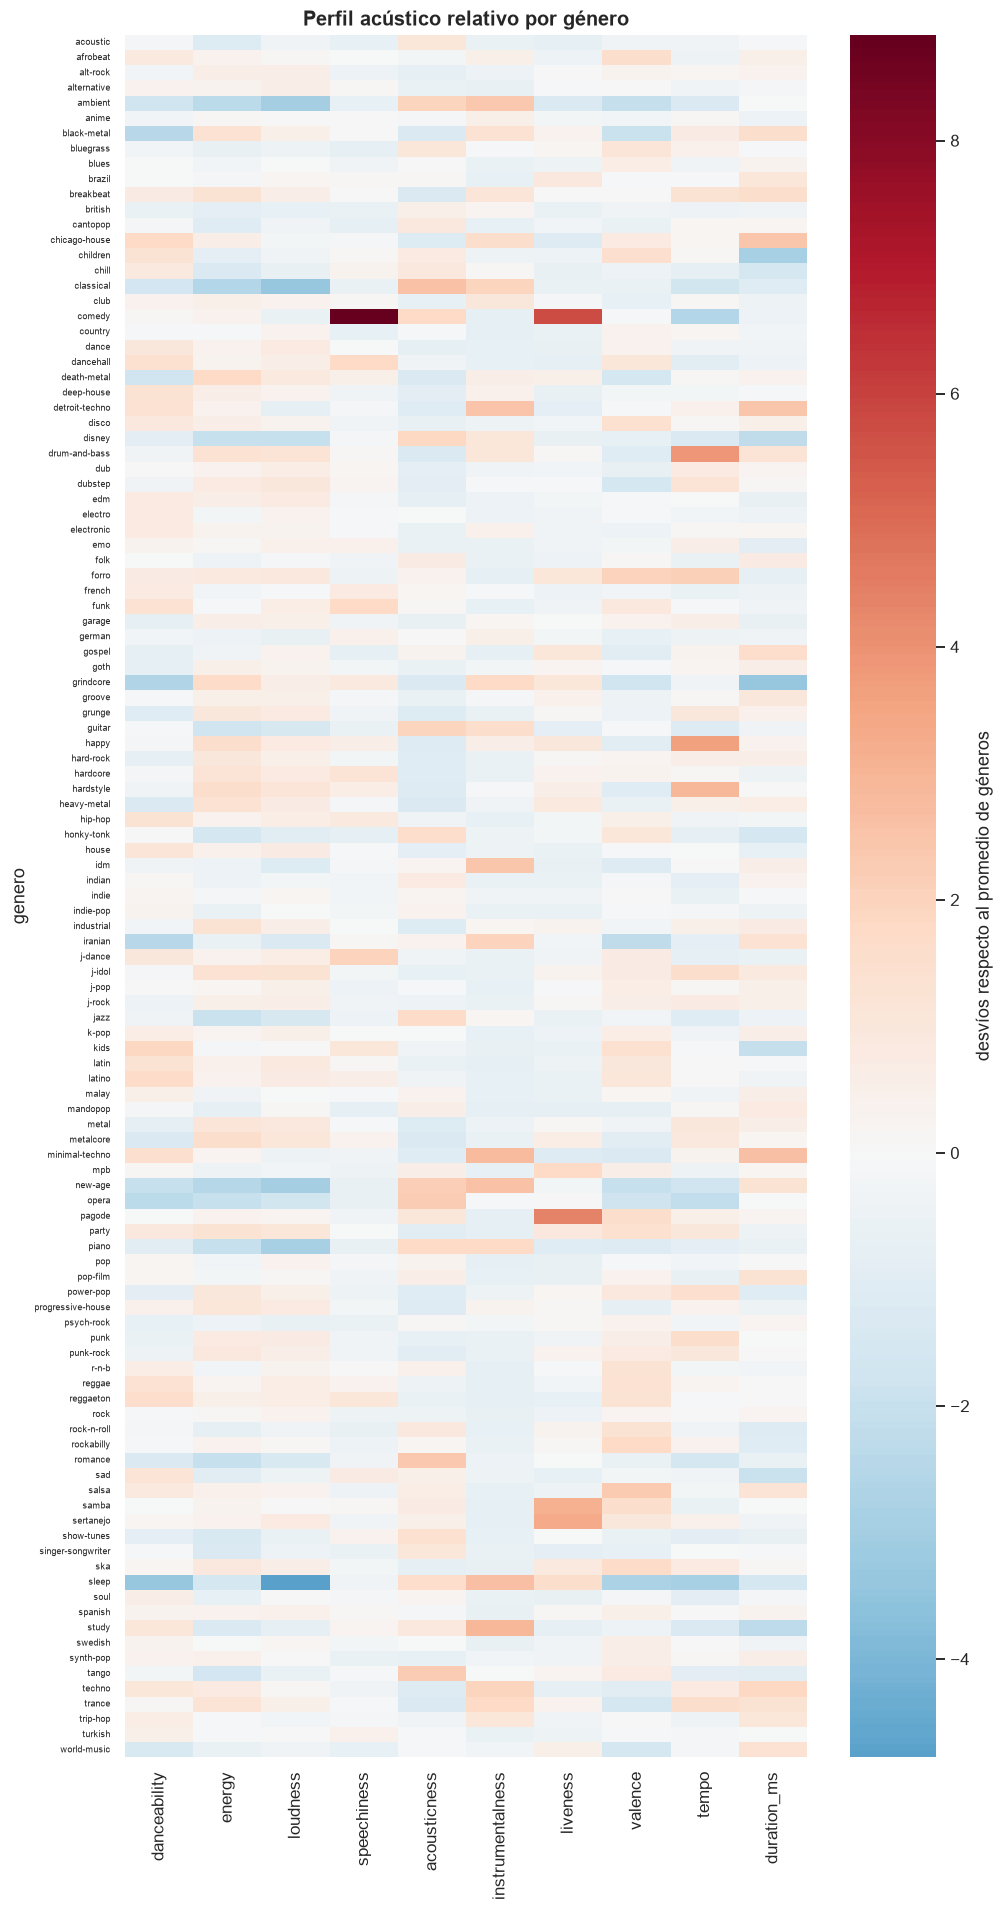

In [10]:
perfil = (X.assign(genero=df[cfg.GENRE_COL].values).groupby("genero").mean())
perfil_z = (perfil - perfil.mean()) / perfil.std()
fig, ax = plt.subplots(figsize=(10, max(5, 0.18 * len(perfil_z))))
sns.heatmap(perfil_z, cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "desvíos respecto al promedio de géneros"},
            yticklabels=True)
ax.grid(False)
ax.tick_params(axis="y", labelsize=6)
ax.set_title("Perfil acústico relativo por género")
viz.save_fig(fig, "eda_06_perfil_por_genero")
plt.show()

## 8. Conclusiones del EDA
> **Completar en equipo tras ejecutar, con números concretos de las tablas de arriba:**
> - Variables con mayor asimetría y qué hicimos con ellas (¿log1p funcionó?).
> - Variables con más outliers y por qué **no** los eliminamos (en música los extremos suelen ser reales: una pista de ruido o de silencio existe).
> - Pares de variables correlacionadas y qué implica para PCA.
> - ¿Qué géneros se parecen entre sí en el heatmap por género? Esto anticipa qué clusters podrían mezclarlos.